# Лабораторная работа №1: линейная регрессия
 по результатам анализа красного вина предсказать его оценку качества `quality`

`RANDOM_STATE = 42` фиксирует случайность (разбиение данных, построение леса), поэтому при каждом запуске получаются одинаковые результаты.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

sns.set_theme(style="darkgrid")
pd.set_option("display.float_format", "{:.3f}".format)
RANDOM_STATE = 42

## Загрузка данных

Данные лежат на UCI в двух CSV-файлах: красные и белые вина. Разделитель в них — `;`. Читаем только файл с красными винами, прямо по ссылке в `DataFrame`. Белые вина в работе не используются, поэтому признак типа вина не нужен.

Признаки — 11 результатов лабораторных анализов: кислотность, остаточный сахар, хлориды, диоксид серы (SO₂), плотность, pH, сульфаты и спирт. Целевая переменная `quality` — медиана оценок как минимум трёх экспертов по шкале 0–10.

In [2]:
# Загрузка данных
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
data = pd.read_csv(url, sep=";")
data.columns = data.columns.str.replace(" ", "_")

data.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5


## Первый осмотр данных

In [3]:
# Первый осмотр: типы, пропуски, дубликаты
data.info()
print("Пропусков:", data.isna().sum().sum())
print("Дубликатов:", data.duplicated().sum())
print("Дубликатов,без учета quality:", data.drop(columns="quality").duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         1599 non-null   float64
 1   volatile_acidity      1599 non-null   float64
 2   citric_acid           1599 non-null   float64
 3   residual_sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free_sulfur_dioxide   1599 non-null   float64
 6   total_sulfur_dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
Пропусков: 0
Дубликатов: 240
Дубликатов,без учета quality: 240


In [4]:
data = data.drop_duplicates()
data.shape

(1359, 12)

- 1599 вин и 12 столбцов. Все признаки числовые, пропусков нет, поэтому заполнять и кодировать ничего не нужно.
- 240 строк (15%) — полные дубликаты. Если не учитывать `quality`, дубликатов столько же, то есть у вин с одинаковыми признаками всегда одинаковая оценка. Скорее всего, это повторные записи одного образца.
- Дубликаты удаляем **до** разбиения на выборки. Иначе копии одного вина попадут и в train, и в test, модель будет «узнавать» вина из теста, и качество окажется завышенным (утечка данных). Если не удалять дубликаты, RMSE случайного леса на тесте падает примерно до 0.56. Но на винах, у которых нет копии в train, ошибка остаётся ≈ 0.64, так что выигрыш ложный.
- После удаления осталось 1359 вин.

## Разбиение на обучающую и тестовую выборки

In [5]:
# Разбиение на train и test
X = data.drop(columns="quality")
y = data["quality"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape)

pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).sort_index()

(1087, 11) (272, 11)


,train,test
quality,,
3,0.007,0.007
4,0.039,0.040
5,0.424,0.426
6,0.394,0.393
7,0.123,0.121
8,0.013,0.011


Размер выбран: 80% / 20%: 1087 вин в train и 272 в test.
- Train достаточно большой, чтобы модели было на чём обучаться.
- Тест из 272 вин — компромисс: данных немного, и если отдать в тест больше, на обучение останется меньше. На таком тесте RMSE менее устойчива: разница между моделями в одну-две сотых может быть случайной. Поэтому дополнительно смотрим на кросс-валидацию по train.

Почему такой способ разбиения?
- Данные перемешиваются, чтобы порядок строк в файле не влиял на то, какие вина попадут в тест.
- `stratify=y`: оценки сильно несбалансированы (во всём наборе оценок 3 и 8 всего 10 и 17). Стратификация сохраняет одинаковые доли каждой оценки в train и test, и таблица выше это подтверждает.
- `random_state=42`: разбиение одинаково при каждом запуске, поэтому все модели сравниваются на одном и том же тесте.

Тест используется только для финальной оценки.
Все решения (выбор модели и её параметров) принимаются по кросс-валидации на train. Train делится на 5 частей, модель 5 раз обучается на четырёх из них и проверяется на пятой (`cross_val_score(..., cv=5)`).

Какие проблемы возникают, если многократно оценивать модели на одном тесте?
Допустим, мы перебираем много вариантов модели и каждый раз смотрим результат на тесте. Тогда:
- тест фактически становится частью обучения: мы подбираем модель под его ответы;
- оценка получается оптимистичной: среди многих вариантов какой-то окажется лучше просто случайно, потому что удачно подошёл к этим 272 винам;
- модель переобучается под конкретный тест и хуже работает на действительно новых данных, например на скрытой тестовой выборке.

## Анализ данных

Анализ делаем только на train, чтобы решения не зависели от ответов тестовой выборки.

In [6]:
train = X_train.assign(quality=y_train)
train.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1087.000,8.330,1.789,4.600,7.100,7.900,9.300,15.900
volatile_acidity,1087.000,0.532,0.186,0.160,0.390,0.520,0.645,1.580
citric_acid,1087.000,0.273,0.197,0.000,0.100,0.260,0.430,1.000
residual_sugar,1087.000,2.533,1.347,0.900,1.900,2.200,2.600,15.500
chlorides,1087.000,0.087,0.048,0.012,0.070,0.079,0.090,0.611
free_sulfur_dioxide,1087.000,16.004,10.616,1.000,7.000,14.000,22.000,72.000
total_sulfur_dioxide,1087.000,47.330,34.333,6.000,22.000,38.000,64.000,289.000
density,1087.000,0.997,0.002,0.990,0.996,0.997,0.998,1.003
pH,1087.000,3.309,0.159,2.740,3.210,3.310,3.400,4.010
sulphates,1087.000,0.656,0.170,0.370,0.550,0.620,0.720,2.000


- Масштабы признаков различаются на порядки: `density` меняется от 0.990 до 1.003, а `total_sulfur_dioxide` — от 6 до 289. Значит, коэффициенты линейной регрессии на исходных данных сравнивать нельзя, понадобится масштабирование.
- У `chlorides`, `residual_sugar`, `sulphates` и `total_sulfur_dioxide` длинные хвосты: максимум намного дальше от 75%-квантиля, чем квантиль от медианы. Например, у хлоридов 75% вин имеют не больше 0.090 г/дм³, а максимум — 0.611; у сахара 75% вин — не больше 2.6, а максимум — 15.5.

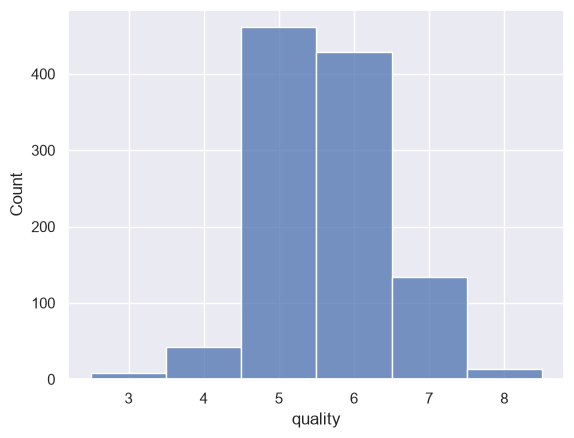

quality
3      8
4     42
5    461
6    428
7    134
8     14
Name: count, dtype: int64

In [7]:
sns.histplot(y_train, discrete=True)
plt.show()
y_train.value_counts().sort_index()

- Оценки несбалансированы: 94% вин имеют оценку 5–7 (82% — только 5 или 6), а оценок 3 и 8 всего 8 и 14. Оценки 9 среди красных вин нет совсем.
- Модель будет учиться в основном на «средних» винах, поэтому редкие оценки она, скорее всего, будет предсказывать хуже.
- Среднее ≈ 5.6, стандартное отклонение ≈ 0.83. Примерно такой RMSE даёт константный прогноз, и чтобы пройти порог 0.70, его нужно улучшить на ~15%.

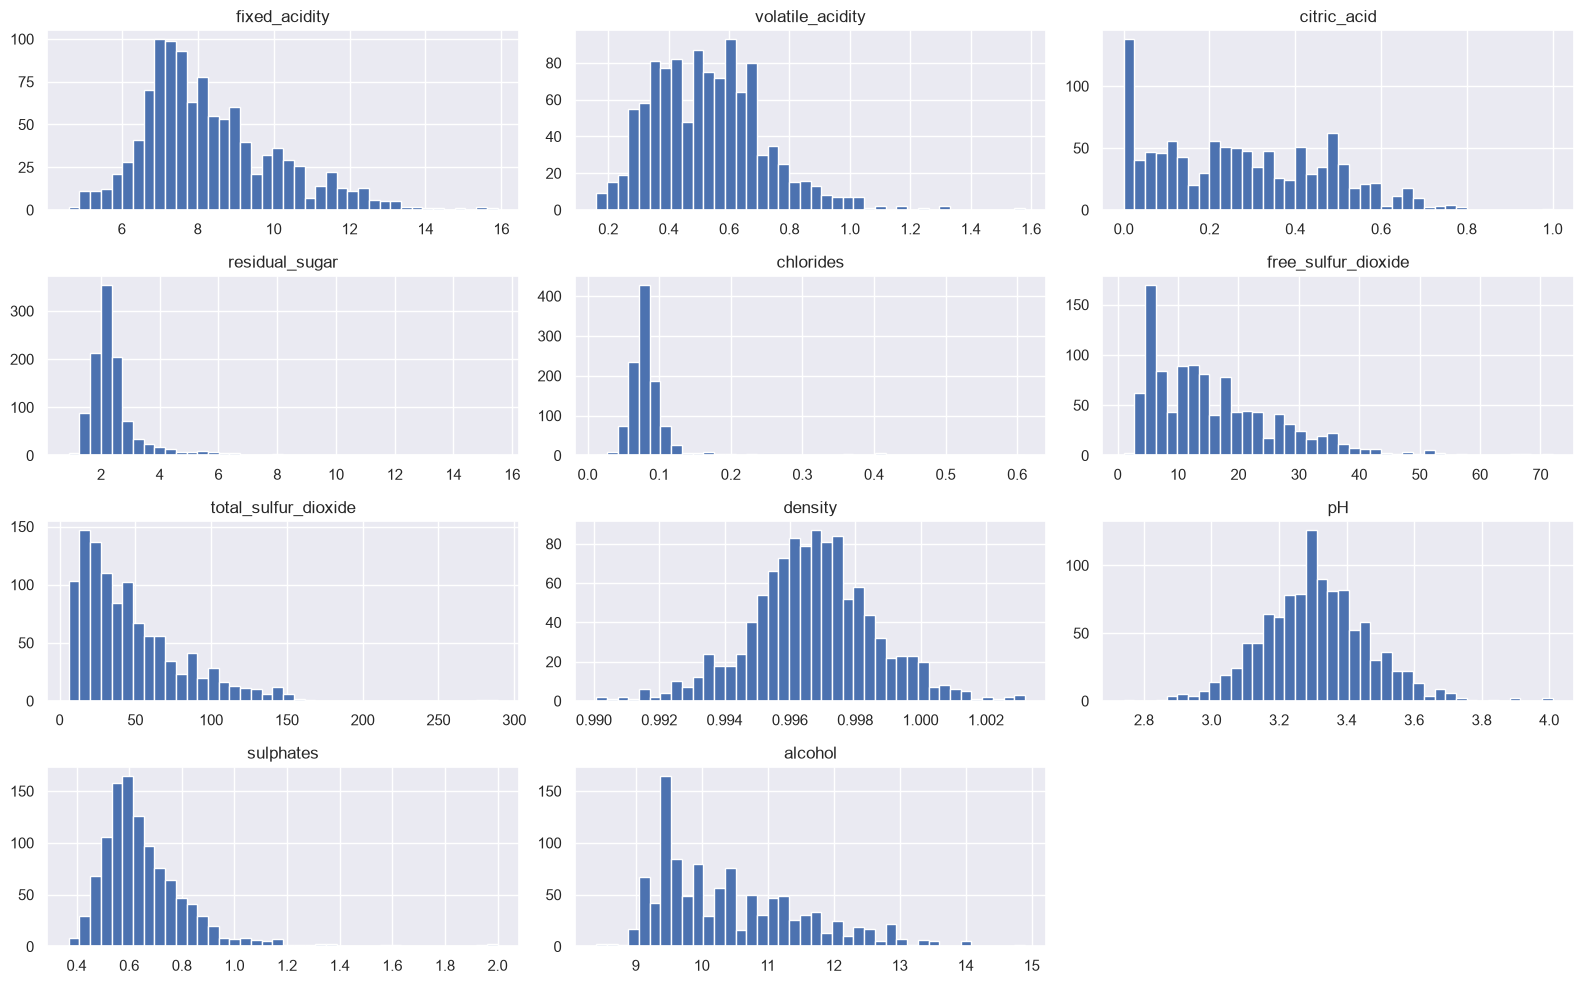

In [8]:
X_train.hist(bins=40, figsize=(16, 10))
plt.tight_layout()
plt.show()

- Большинство признаков скошены вправо, особенно `chlorides`, `residual_sugar` и `sulphates`: у большинства вин значения небольшие, но встречаются вина с очень большими.
- Крупные значения — реальные вина, а не ошибки, поэтому их не удаляем. Деревья к таким значениям устойчивы, линейная регрессия чувствительнее.

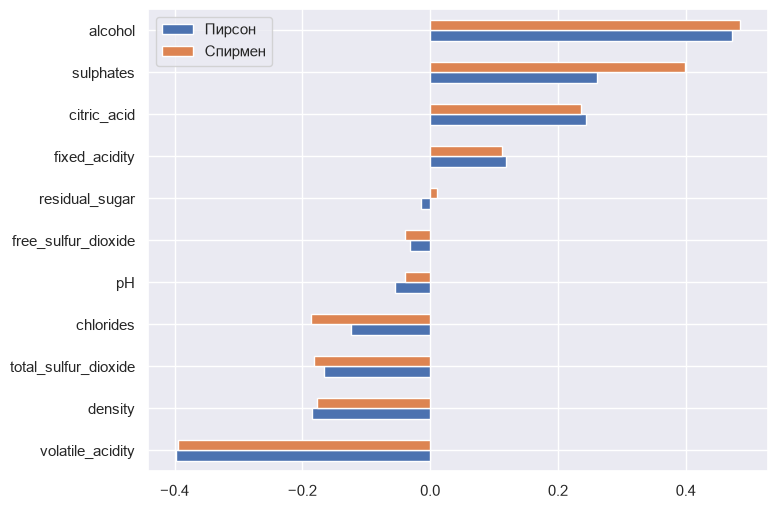

,Пирсон,Спирмен
alcohol,0.472,0.485
sulphates,0.261,0.399
volatile_acidity,-0.397,-0.395
citric_acid,0.244,0.236
chlorides,-0.124,-0.187
total_sulfur_dioxide,-0.165,-0.181
density,-0.184,-0.178
fixed_acidity,0.119,0.112
pH,-0.055,-0.040
free_sulfur_dioxide,-0.032,-0.039


In [9]:
corr = pd.DataFrame({
    "Пирсон": X_train.corrwith(y_train),
    "Спирмен": X_train.corrwith(y_train, method="spearman"),
})
corr.sort_values("Пирсон").plot(kind="barh", figsize=(8, 6))
plt.show()
corr.sort_values("Спирмен", key=abs, ascending=False)

- **`alcohol`** — самая сильная связь с качеством (r ≈ 0.47): чем больше спирта, тем выше оценка.
  - Вероятно, это отражает зрелость винограда: больше сахара в ягодах — больше спирта и насыщеннее вкус.
  - При этом r² ≈ 0.22, то есть даже этот признак объясняет лишь пятую часть разброса оценок. Одного его мало, но учитывать в модели его обязательно.
- **`volatile_acidity`** (r ≈ −0.40) — вторая по силе связь. Летучие кислоты дают уксусный привкус, а это дефект вина. Признак очень полезен.
- **`sulphates`** (r ≈ 0.26, по Спирмену 0.40): сульфаты поддерживают уровень SO₂, который защищает вино от окисления и микробов. По Спирмену связь заметно сильнее, чем по Пирсону. Значит, она монотонная, но не линейная, а выбросы (до 2.0 при медиане 0.62) «портят» линейную корреляцию.
- **`citric_acid`** (r ≈ 0.24): лимонная кислота добавляет свежести. Но она сильно связана с летучей кислотностью (−0.54) и общей кислотностью, так что часть этой связи — отражение других признаков.
- **`total_sulfur_dioxide`** (−0.17), **`chlorides`** (−0.12) и **`density`** (−0.18) — слабые отрицательные связи. Плотность в основном отражает спирт и кислотность (корреляции −0.52 и 0.68), новой информации почти не добавляет.
- У `pH`, `free_sulfur_dioxide` и `residual_sugar` связи с качеством почти нет (|r| < 0.06). Проверим ниже, нет ли у них нелинейной зависимости.

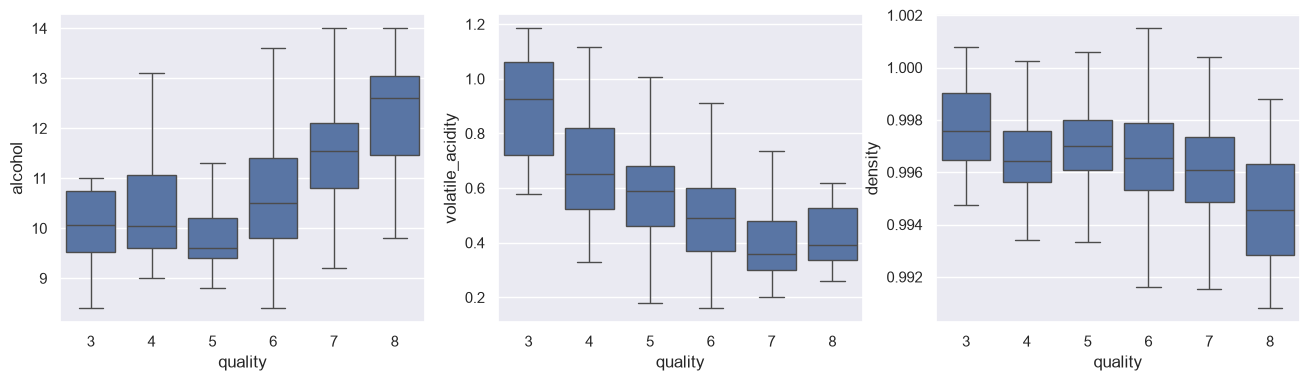

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axs, ["alcohol", "volatile_acidity", "density"]):
    sns.boxplot(x=y_train, y=X_train[feature], showfliers=False, ax=ax)
plt.show()

- Медиана спирта растёт с оценкой: от 9.6% у оценки 5 до 11.6% у оценки 7 и 12.6% у оценки 8.
- У худших вин (3–4) спирта не меньше, чем у вин с оценкой 5 (≈10.1%), но намного выше летучая кислотность: медиана 0.93 у оценки 3 и 0.65 у оценки 4 против 0.49 у оценки 6. Портит их именно она.
- Летучая кислотность почти монотонно падает с ростом оценки (с 0.93 до 0.36–0.39), а плотность немного снижается зеркально спирту.

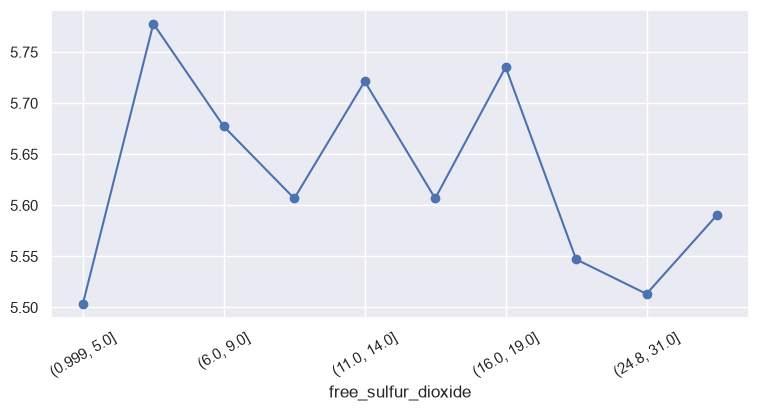

In [11]:
train.groupby(pd.qcut(train["free_sulfur_dioxide"], 10), observed=True)["quality"].mean().plot(marker="o", rot=30, figsize=(9, 4))
plt.show()

- У красных вин качество от `free_sulfur_dioxide` почти не зависит: средняя оценка во всех десяти группах колеблется между 5.5 и 5.8 без явной закономерности.
- Это согласуется с почти нулевой корреляцией (−0.03). Скорее всего, признак малоинформативен; проверим это по важности признаков в моделях.

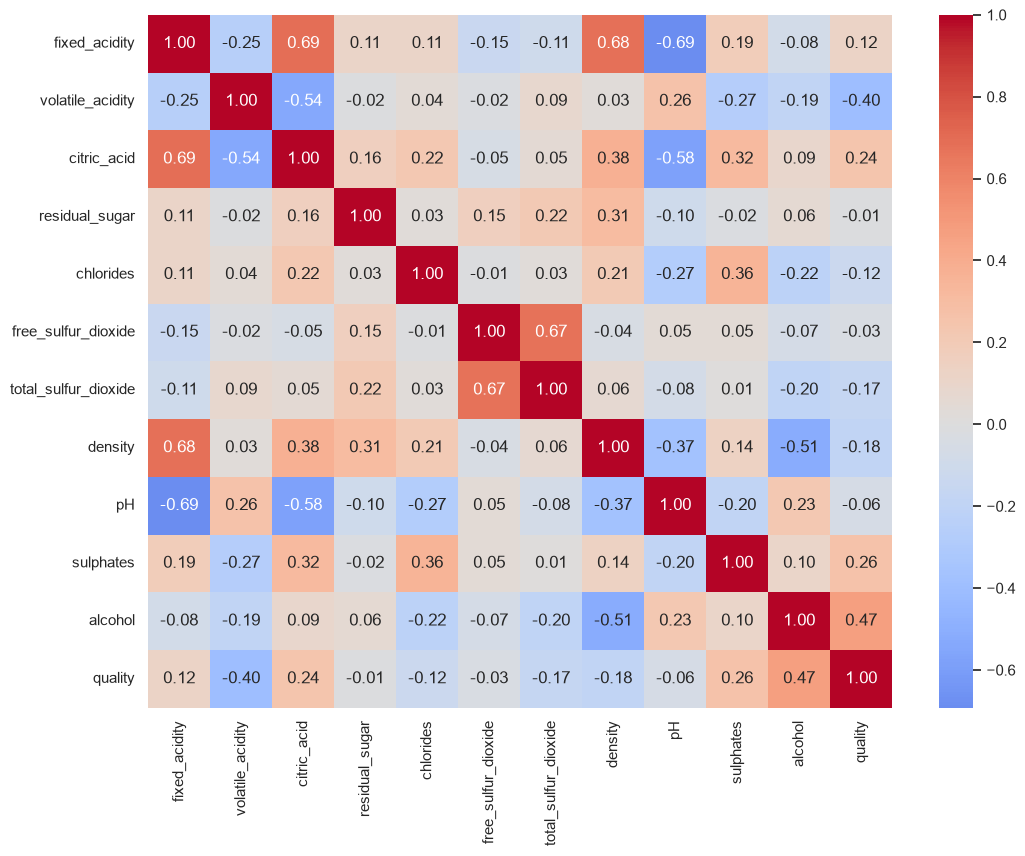

In [12]:
plt.figure(figsize=(12, 9))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

- Некоторые признаки сильно связаны между собой:
  - `fixed_acidity` с `pH` (−0.69), `citric_acid` (0.69) и `density` (0.68): все они описывают кислотность вина;
  - `free_sulfur_dioxide` и `total_sulfur_dioxide` (0.67): свободный SO₂ — часть общего;
  - `citric_acid` с `volatile_acidity` (−0.54), `alcohol` с `density` (−0.52).
- Это мультиколлинеарность: такие признаки дублируют информацию. Это нужно учитывать, когда интерпретируем коэффициенты линейной модели и важность признаков.

- Важнее всего `alcohol` (+), `volatile_acidity` (−) и `sulphates` (+).
- Сильных линейных связей нет: максимум |r| ≈ 0.47.
- Главные зависимости близки к монотонным, но есть и нелинейность (у `sulphates`). Поэтому ожидаем, что случайный лес и бустинг окажутся лучше линейной регрессии, но разница может быть небольшой.

## Метрики и baseline

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat y_i| \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat y_i)^2}$$

**MAE** Средний модуль ошибки: на сколько баллов в среднем ошибается модель. Каждая ошибка учитывается пропорционально своей величине.

**RMSE** Корень из среднего квадрата ошибки. Измеряется тоже в баллах, но крупные ошибки в нём весят больше.

**Почему RMSE сильнее реагирует на большие ошибки.** Ошибки возводятся в квадрат до усреднения. Ошибка 0.5 даёт вклад 0.25, а ошибка 3 — вклад 9. Получается, одна ошибка в 3 балла весит столько же, сколько 36 ошибок по 0.5.

**Почему MAE и RMSE одной модели могут заметно различаться.** Всегда RMSE ≥ MAE. Равны они, только если все ошибки одинаковы по модулю. Чем больше среди ошибок редких крупных промахов, тем больше разрыв.

**Baseline** — предсказание одной константой для всех вин. Для RMSE оптимальная константа — среднее значение target: производная суммы $\sum (y_i - c)^2$ по $c$ равна нулю при $c = \bar y$. Для MAE оптимальной была бы медиана. Среднее считаем только по train.

In [13]:
# Baseline: среднее quality по train
y_pred_baseline = np.full(len(y_test), y_train.mean())
results = {"Baseline": {
    "RMSE": root_mean_squared_error(y_test, y_pred_baseline),
    "MAE": mean_absolute_error(y_test, y_pred_baseline),
}}
results["Baseline"]

{'RMSE': 0.8191269109653824, 'MAE': 0.692065993830835}

**Результат:** RMSE = 0.819, MAE = 0.692. RMSE baseline практически равен стандартному отклонению `quality` (0.825). Это точка отсчёта: если модель не лучше этих чисел, она не извлекает из признаков полезной информации.

## Модели

- **Linear Regression.** Прогноз — взвешенная сумма признаков, веса подбираются минимизацией MSE. Перед моделью стоит `StandardScaler` внутри `Pipeline`. Масштаб считается только по обучающей части (в том числе внутри кросс-валидации), поэтому информация из теста не утекает.
- **Random Forest.** Прогноз — среднее 300 глубоких деревьев, каждое обучено на своей случайной подвыборке. `max_features="sqrt"` значит, что в каждом узле дерево выбирает разбиение из ~3 случайных признаков. Деревья получаются разнообразнее, и усреднение лучше гасит их ошибки.
- **Gradient Boosting.** Деревья строятся последовательно: каждое следующее обучается на ошибках (остатках) предыдущих и добавляется с маленьким шагом `learning_rate`. Параметры (300 деревьев, `learning_rate=0.05`, `max_depth=6`, `subsample=0.8`) подбирались по кросс-валидации на полном датасете (красные и белые вина). Для одних красных вин их заново не подбирали.

Для каждой модели считаем:
- RMSE на кросс-валидации по train — по нему выбираем лучшую модель;
- RMSE на train — чтобы увидеть переобучение;
- RMSE и MAE на тесте.

In [14]:
# Модели: Linear Regression, Random Forest, Gradient Boosting
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1),
    # параметры бустинга подбирались по кросс-валидации на полном датасете (красные + белые вина)
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                                   min_samples_leaf=5, random_state=RANDOM_STATE),
}

for name, model in models.items():
    cv_rmse = -cross_val_score(model, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error").mean()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {
        "CV RMSE": cv_rmse,
        "RMSE train": root_mean_squared_error(y_train, model.predict(X_train)),
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
    }

## Честное сравнение моделей

Все модели обучены на одной обучающей выборке, проверены по одной схеме кросс-валидации и оценены на одной тестовой выборке. Для выбора параметров тест не использовался.

In [15]:
# Итоговая таблица
pd.DataFrame(results).T

,RMSE,MAE,CV RMSE,RMSE train
Baseline,0.819,0.692,NaN,NaN
Linear Regression,0.652,0.507,0.670,0.660
Random Forest,0.632,0.489,0.635,0.236
Gradient Boosting,0.648,0.495,0.660,0.141


**Какие модели превзошли baseline.** Все три. Порог RMSE < 0.70 тоже проходят все модели: Random Forest (0.632), Gradient Boosting (0.648) и Linear Regression (0.652).

**Почему результаты различаются.**
- **Random Forest — лучший результат** и на тесте (0.632), и на кросс-валидации (0.635).
  - Деревья разбивают признаки на интервалы и строят отдельные ветви для разных групп вин. Поэтому они улавливают нелинейности и взаимодействия признаков.
  - Усреднение 300 разных деревьев гасит их переобучение.
  - Низкая ошибка на train (0.236) для леса нормальна: каждое дерево почти запоминает свою выборку. Честные оценки — кросс-валидация (0.635) и тест (0.632) — согласуются между собой.
- **Linear Regression не переобучается** (train 0.660, CV 0.670, тест 0.652) и тоже проходит порог.
  - У красных вин главные зависимости (спирт, летучая кислотность, сульфаты) близки к монотонным, поэтому линейная модель справляется неплохо.
  - Отставание от леса (≈0.02 на тесте и ≈0.035 по CV) — это нелинейности, например у `sulphates`, которые прямая описать не может.
- **Gradient Boosting сильно переобучен:** ошибка на train 0.141 против 0.660 на кросс-валидации. Его параметры (300 деревьев глубины 6) подбирались на полном датасете, а для 1087 красных вин такие деревья слишком сложные, и модель подгоняется под шум в оценках.
- Тест маленький (272 вина), поэтому разница между моделями в 0.01–0.02 может быть случайной. Устойчивее порядок по кросс-валидации: Random Forest (0.635), Gradient Boosting (0.660), Linear Regression (0.670).
- **Даже лучшая модель ошибается в среднем на ~0.5 балла** (MAE 0.489). В данных нет сорта винограда, года урожая и аромата, а оценка — мнение нескольких людей.

## Линейная регрессия: коэффициенты

Веса модели хранятся в атрибуте `coef_`. Сравним веса модели, обученной на исходных данных, и модели после `StandardScaler`.

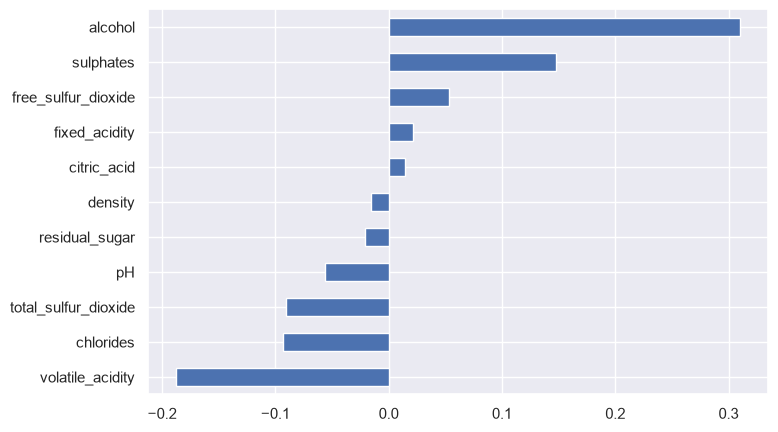

,без масштабирования,после StandardScaler
volatile_acidity,-1.010,-0.187
chlorides,-1.951,-0.093
total_sulfur_dioxide,-0.003,-0.090
pH,-0.356,-0.056
residual_sugar,-0.015,-0.021
density,-7.922,-0.015
citric_acid,0.073,0.014
fixed_acidity,0.012,0.022
free_sulfur_dioxide,0.005,0.053
sulphates,0.872,0.148


In [16]:
# Коэффициенты линейной регрессии: без масштабирования и после StandardScaler
coefs = pd.DataFrame({
    "без масштабирования": LinearRegression().fit(X_train, y_train).coef_,
    "после StandardScaler": models["Linear Regression"][-1].coef_,
}, index=X.columns).sort_values("после StandardScaler")

coefs["после StandardScaler"].plot(kind="barh", figsize=(8, 5))
plt.show()
coefs

- **Масштабирование нужно, чтобы интерпретировать веса.**
  - На исходных данных самый большой по модулю вес у `density` (−7.9), у остальных признаков — от 0.003 до 2.
  - Это не значит, что плотность важнее всего. Она меняется всего на ~0.002 (std), и изменение «на 1 г/см³» физически невозможно. Большой коэффициент здесь — следствие маленького масштаба признака: после масштабирования вес плотности почти нулевой (−0.015).
- **После `StandardScaler` веса можно сравнивать.**
  - Теперь вес показывает, как меняется прогноз при изменении признака на одно стандартное отклонение.
  - Прогнозы модели от масштабирования не меняются, меняются только единицы весов: вес после масштабирования = вес до × std признака.
- **Наибольшее влияние:** `alcohol` (+0.31), `volatile_acidity` (−0.19), `sulphates` (+0.15), затем `chlorides` и `total_sulfur_dioxide` (≈ −0.09). Знаки совпадают с анализом данных.
- **Веса связанных признаков нужно трактовать осторожно.**
  - `free_sulfur_dioxide` получила положительный вес (+0.05), хотя её корреляция с качеством около нуля, а у `total_sulfur_dioxide` вес отрицательный. Эти признаки связаны (0.67), и модель «компенсирует» один другим.
  - `citric_acid` и `fixed_acidity` положительно связаны с качеством, но их веса почти нулевые: эту информацию модель уже берёт из летучей кислотности, pH и плотности.
  - Это мультиколлинеарность, поэтому по отдельности такие веса нельзя трактовать как влияние признака.

## Feature importance: Random Forest и Gradient Boosting

`feature_importances_` показывает, насколько в сумме уменьшилась ошибка (MSE) во всех разбиениях деревьев по этому признаку. Значения нормированы так, что их сумма равна 1.

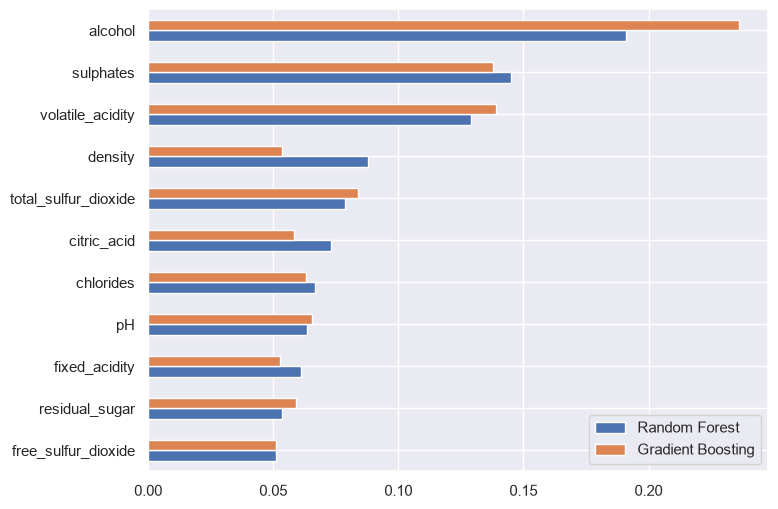

,Random Forest,Gradient Boosting
alcohol,0.191,0.236
sulphates,0.145,0.138
volatile_acidity,0.129,0.139
density,0.088,0.053
total_sulfur_dioxide,0.079,0.084
citric_acid,0.073,0.058
chlorides,0.067,0.063
pH,0.064,0.066
fixed_acidity,0.061,0.053
residual_sugar,0.054,0.059


In [17]:
# Feature importance: Random Forest и Gradient Boosting
importances = pd.DataFrame({
    "Random Forest": models["Random Forest"].feature_importances_,
    "Gradient Boosting": models["Gradient Boosting"].feature_importances_,
}, index=X.columns).sort_values("Random Forest")

importances.plot(kind="barh", figsize=(8, 6))
plt.show()
importances.sort_values("Random Forest", ascending=False)

**Random Forest.**
- Самые важные признаки: `alcohol` (0.19), `sulphates` (0.15), `volatile_acidity` (0.13), затем `density` (0.09) и `total_sulfur_dioxide` (0.08).
- Это совпадает с анализом данных и линейной регрессией: спирт, сульфаты и летучая кислотность — главные факторы.
- `free_sulfur_dioxide` на последнем месте, как и ожидалось по анализу данных: от неё качество красных вин почти не зависит.

**Gradient Boosting.** Главный признак тоже `alcohol` (0.24), затем `volatile_acidity` (0.14) и `sulphates` (0.14).

**Сравнение RF и GB.**
- Тройка ключевых признаков у моделей общая.
- Главное отличие — `density`: у леса она на 4-м месте, у бустинга на 9-м.
  - Лес в каждом узле видит лишь ~3 случайных признака. Когда спирта или кислотности среди них нет, он берёт плотность как замену: она связана с обоими.
  - Бустинг выбирает из всех признаков и берёт сам `alcohol`, поэтому сильнее концентрирует важность на спирте (0.24 против 0.19).
- Остальные признаки у обеих моделей имеют близкие небольшие важности (0.05–0.08).

In [18]:
# Ранги важности (1 — самый важный): EDA, линейная регрессия, RF, GB
pd.DataFrame({
    "EDA |Спирмен|": corr["Спирмен"].abs(),
    "LinReg |коэф.|": coefs["после StandardScaler"].abs(),
    "Random Forest": importances["Random Forest"],
    "Gradient Boosting": importances["Gradient Boosting"],
}).rank(ascending=False).astype(int).sort_values("Random Forest")

,EDA |Спирмен|,LinReg |коэф.|,Random Forest,Gradient Boosting
alcohol,1,1,1,1
sulphates,2,3,2,3
volatile_acidity,3,2,3,2
density,7,10,4,9
total_sulfur_dioxide,6,5,5,4
citric_acid,4,11,6,8
chlorides,5,4,7,6
pH,9,6,8,5
fixed_acidity,8,8,9,10
residual_sugar,11,9,10,7


**Сопоставление с анализом данных** (ранг 1 — самый важный признак).
- Тройка `alcohol`, `sulphates`, `volatile_acidity` занимает первые три места во всех четырёх методах: по корреляции, в линейной регрессии и в обеих моделях на деревьях. `alcohol` везде на первом месте. Это самый надёжный вывод работы.
- `density` по корреляции на 7-м месте, в линейной модели на 10-м, у бустинга на 9-м, и только у леса на 4-м: она дублирует информацию о спирте и кислотности.
- `citric_acid` по корреляции на 4-м месте, а в моделях ниже (6–11): её связь с качеством во многом объясняется летучей кислотностью и сульфатами.
- `free_sulfur_dioxide` и `residual_sugar` почти везде внизу, как и в анализе данных.

**Можно ли по feature importance утверждать, что изменение признака — причина изменения качества вина? Нет.**
- Feature importance показывает, на какие признаки опирается модель при прогнозе, а не что влияет на вино в реальности.
- Модель использует любые статистические связи, в том числе не причинные. Например, высокий спирт и высокая оценка могут оба быть следствием спелого винограда хорошего года. Если просто добавить спирт в вино, лучше оно не станет.
- Коррелированные признаки подменяют друг друга: важность `density` сильно зависит от модели, хотя данные одни и те же.
- Чтобы доказать причинность, нужен эксперимент: изменить один параметр у одинаковых вин и провести слепую дегустацию.

## Анализ ошибок лучшей модели

Лучшую модель выбираем по RMSE на кросс-валидации, а не по тесту: это Random Forest. Ошибка = прогноз − истинная оценка.

In [19]:
# Анализ ошибок лучшей модели (по CV RMSE)
best_name = pd.DataFrame(results).T["CV RMSE"].idxmin()
y_pred = pd.Series(models[best_name].predict(X_test), index=y_test.index, name="prediction")
errors = (y_pred - y_test).rename("error")       # > 0 — модель завысила оценку, < 0 — занизила
print(best_name)
errors.describe()

Random Forest


count   272.000
mean      0.031
std       0.632
min      -1.877
25%      -0.380
50%       0.092
75%       0.390
max       2.250
Name: error, dtype: float64

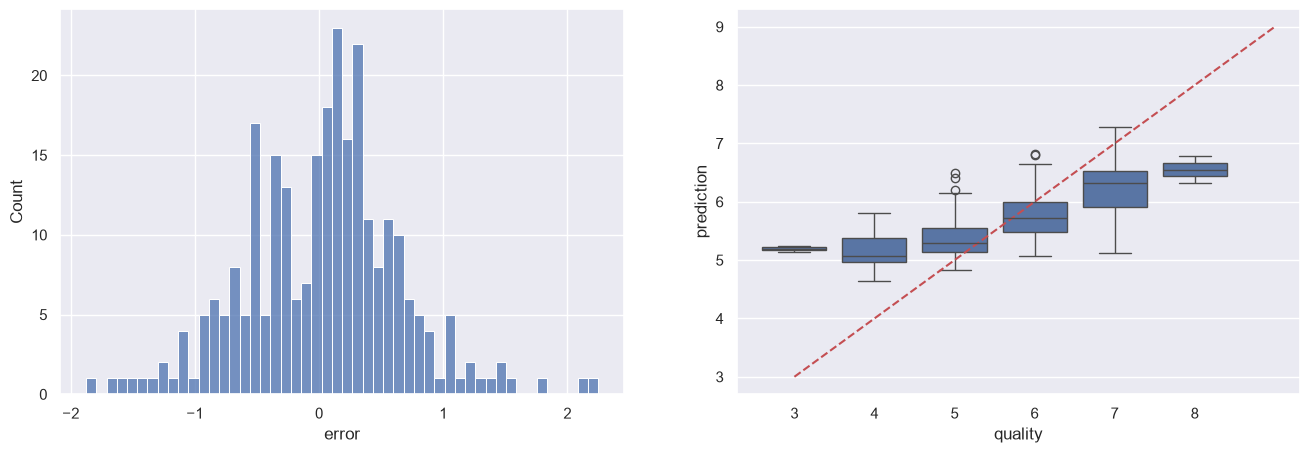

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(errors, bins=50, ax=axs[0])
sns.boxplot(x=y_test, y=y_pred, ax=axs[1])
axs[1].plot(range(7), range(3, 10), "r--")      # идеальный прогноз
plt.show()

**Распределение ошибок** симметрично и сосредоточено около нуля.
- Средняя ошибка +0.03.
- Половина вин предсказана с ошибкой от −0.38 до +0.39.
- Крупных промахов немного; самые большие — −1.88 и +2.25.

**Истинные и предсказанные значения.** Прогнозы прижаты к середине шкалы: для плохих вин (3–4) они выше истинных, для хороших (7–8) — ниже. «Ящики» крайних оценок лежат далеко от диагонали идеального прогноза.

In [21]:
pd.DataFrame({
    "вин в train": y_train.value_counts(),
    "вин в test": y_test.value_counts(),
    "средний прогноз": y_pred.groupby(y_test).mean(),
    "MAE": errors.abs().groupby(y_test).mean(),
    "RMSE": (errors ** 2).groupby(y_test).mean() ** 0.5,
}).sort_index()

,вин в train,вин в test,средний прогноз,MAE,RMSE
quality,,,,,
3,8,2,5.197,2.197,2.197
4,42,11,5.148,1.148,1.198
5,461,116,5.382,0.386,0.492
6,428,107,5.779,0.385,0.459
7,134,33,6.243,0.774,0.890
8,14,3,6.549,1.451,1.463


In [22]:
pd.crosstab(y_test, y_pred.round().astype(int), rownames=["quality"], colnames=["округлённый прогноз"])

округлённый прогноз,5,6,7
quality,,,
3,2,0,0
4,9,2,0
5,83,33,0
6,30,69,8
7,3,20,10
8,0,1,2


**Одинаково ли хорошо модель работает для разных значений quality? Нет.**
- Лучше всего модель работает для частых оценок 5 и 6 (RMSE 0.49 и 0.46).
- Плохие вина она переоценивает: при оценке 3 в среднем предсказывает 5.20, при оценке 4 — 5.15.
- Хорошие вина недооценивает: при оценке 7 предсказывает 6.24, при оценке 8 — 6.55.
- Округлённые прогнозы лежат только в диапазоне 5–7. Модель ни разу не предсказала 3, 4 или 8, а из 33 вин с оценкой 7 верный прогноз получили только 10 (ещё 20 — прогноз 6).
- В тесте всего 2 вина с оценкой 3 и 3 вина с оценкой 8, поэтому ошибки по этим оценкам — ориентир, а не точное значение.

**Почему редкие значения quality предсказываются хуже.**
- Мало примеров: оценок 3 в train всего 8, оценок 8 — 14.
- Прогноз дерева — среднее оценок вин в листе. Рядом с редкой «тройкой» почти всегда окажутся «пятёрки» и «шестёрки», и прогноз уходит к центру. Лес дополнительно усредняет 300 деревьев.
- Модель минимизирует среднюю квадратичную ошибку. При неуверенности ей выгоднее предсказывать ближе к среднему: промах к центру в среднем обходится дешевле.
- Крайние оценки часто объясняются тем, чего нет в данных: дефектами запаха, ароматом, сложностью вкуса.

In [23]:
# Вина с самыми большими ошибками и типичные значения признаков для каждой оценки
worst = X_test.assign(quality=y_test, prediction=y_pred, error=errors).loc[errors.abs().sort_values(ascending=False).index]
display(worst.head(10))
train.groupby("quality").median()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,prediction,error
832,10.400,0.440,0.420,1.500,0.145,34.000,48.000,0.998,3.380,0.860,9.900,3,5.250,2.250
1374,6.800,0.815,0.000,1.200,0.267,16.000,29.000,0.995,3.320,0.510,9.800,3,5.143,2.143
7,7.300,0.650,0.000,1.200,0.065,15.000,21.000,0.995,3.390,0.470,10.000,7,5.123,-1.877
703,7.500,0.380,0.480,2.600,0.073,22.000,84.000,0.997,3.320,0.700,9.600,4,5.800,1.800
495,10.700,0.350,0.530,2.600,0.070,5.000,16.000,0.997,3.150,0.650,11.000,8,6.323,-1.677
1466,7.300,0.480,0.320,2.100,0.062,31.000,54.000,0.997,3.300,0.650,10.000,7,5.427,-1.573
1233,10.200,0.230,0.370,2.200,0.057,14.000,36.000,0.996,3.230,0.490,9.300,4,5.513,1.513
645,7.800,0.640,0.100,6.000,0.115,5.000,11.000,0.998,3.370,0.690,10.100,7,5.493,-1.507
1509,7.900,0.180,0.400,1.800,0.062,7.000,20.000,0.994,3.280,0.700,11.100,5,6.487,1.487
1202,8.600,0.420,0.390,1.800,0.068,6.000,12.000,0.995,3.350,0.690,11.700,8,6.543,-1.457


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,7.500,0.927,0.035,2.150,0.083,5.500,14.000,0.998,3.440,0.545,10.075
4,7.500,0.653,0.085,2.100,0.080,11.000,29.000,0.996,3.380,0.560,10.050
5,7.800,0.590,0.220,2.200,0.082,15.000,48.000,0.997,3.290,0.580,9.600
6,7.900,0.490,0.270,2.200,0.078,14.000,37.000,0.997,3.310,0.640,10.500
7,8.800,0.360,0.400,2.300,0.073,11.000,26.500,0.996,3.280,0.740,11.550
8,7.850,0.390,0.335,2.000,0.071,13.500,29.000,0.995,3.230,0.750,12.600


**Разбор объектов с самыми большими ошибками.** Сравниваем их признаки с медианными значениями для каждой оценки.
- **Вино 832: оценка 3, прогноз 5.25.**
  - По основным признакам вино выглядит средним или даже неплохим. Летучая кислотность 0.44 — как у типичной «шестёрки» (0.49), а не «тройки» (0.93). Сульфатов много (0.86), как у вин с оценками 7–8.
  - Единственный тревожный сигнал — много хлоридов (0.145 при типичных ~0.08), но этого мало, чтобы модель поставила 3.
  - Низкую оценку, видимо, определил дефект, которого нет в данных (например, посторонний запах).
- **Вино 1374: оценка 3, прогноз 5.14.**
  - Признаки указывают на плохое вино: высокая летучая кислотность (0.815), очень много хлоридов (0.267), нет лимонной кислоты.
  - Модель верно определила направление: это один из самых низких её прогнозов. Но из-за сжатия к центру она не опустилась до 3; вин с оценкой 3 в train всего 8.
- **Вино 7: оценка 7, прогноз 5.12.**
  - Химический состав говорит о слабом вине: летучая кислотность 0.65 (как у «четвёрок»), нет лимонной кислоты, мало сульфатов (0.47 при 0.74 у «семёрок»), спирт 10% (у «семёрок» 11.6%).
  - Эксперты тем не менее поставили 7. Это пример шума в разметке или факторов, которых нет в данных (аромат, вкус).
- **Вино 703: оценка 4, прогноз 5.80.**
  - Обратная ситуация: низкая летучая кислотность (0.38), много лимонной кислоты (0.48) и сульфатов (0.70), как у хороших вин. Мало только спирта (9.6%).
  - Модель видит «хорошую» химию и ставит почти 6, хотя эксперты оценили вино на 4.

## Итоговые выводы
1. **Подготовка данных.** Используются только красные вина: из 1599 записей удалены 240 дубликатов, чтобы избежать утечки между train и test, осталось 1359 вин. Разбиение 80/20 со стратификацией, все решения принимались по кросс-валидации на train.
2. **Результаты моделей.**
   - Все модели лучше baseline (RMSE 0.819) и проходят порог 0.70.
   - **Лучшая модель — Random Forest: RMSE 0.632, MAE 0.489** (CV RMSE 0.635).
   - Gradient Boosting (0.648) и Linear Regression (0.652) немного хуже. Бустинг с параметрами, подобранными на полном датасете, на красных винах переобучается.
3. **Главные признаки — `alcohol` (+), `sulphates` (+) и `volatile_acidity` (−).** На первые три места их ставят все методы: корреляция, линейная регрессия и обе модели на деревьях.
4. **Feature importance не доказывает причинность.**
5. **Модель хорошо предсказывает типичные вина (5–6) и плохо — редкие крайние оценки (3–4 и 8).**